# 线性最小二乘的数学原理

In [1]:
from pathlib import Path
import sys
root = Path.cwd().resolve()
while not (root / 'lsq').is_dir():
    if root == root.parent:
        raise RuntimeError('Run inside the repository')
    root = root.parent
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import least_squares
from lsq import (finite_difference, whiten, gauss_newton,
                 levenberg_marquardt, dogleg, recursive_update)
np.set_printoptions(precision=5, suppress=True)
plt.rcParams.update({'figure.figsize': (6.4, 3.3), 'font.size': 10,
                     'axes.grid': True, 'savefig.dpi': 130})

第01章的两条偏导方程，可以写成一个对任意参数数量都适用的矩阵形式。设$A\in\mathbb R^{m\times n}$，每行描述一次观测对参数的线性响应，模型为$Ax$。

## 从目标到正规方程

$$F(x)=\frac12(Ax-y)^T(Ax-y),\qquad \nabla F(x)=A^T(Ax-y).$$

极小点满足$A^TAx=A^Ty$，这就是正规方程。若$A$满列秩，$A^TA$对称正定，解唯一；若秩亏，拟合值仍唯一，但不同参数可给出同一拟合值。

实际编程不推荐显式计算$(A^TA)^{-1}$。正规方程用于理解数学，数值求解优先使用QR/SVD，第04章会说明原因。

## 几何上是在做投影

$Ax$只能落在$A$的列空间里。最优拟合$\hat y=Ax^*$是$y$在该空间上的正交投影，因此残差$r=\hat y-y$与每一列正交，即$A^Tr=0$。这也说明：每增加一列，允许的拟合空间变大，训练误差不会上升，但预测误差未必下降。

coefficient: 0.6 orthogonality: 0.0


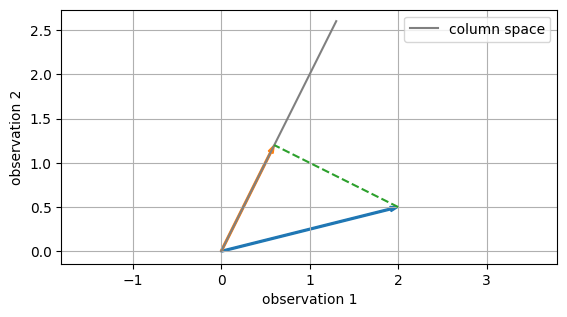

In [2]:
v = np.array([1., 2.]); y = np.array([2., .5])
x = (v@y)/(v@v)
projected = x*v
print('coefficient:', x, 'orthogonality:', v@(projected-y))
assert np.isclose(v@(projected-y), 0.)
plt.plot([0, 1.3], [0, 2.6], color='gray', label='column space')
plt.arrow(0, 0, *y, width=.02, color='C0', length_includes_head=True)
plt.arrow(0, 0, *projected, width=.02, color='C1', length_includes_head=True)
plt.plot([y[0], projected[0]], [y[1], projected[1]], '--', color='C2')
plt.axis('equal'); plt.xlabel('observation 1'); plt.ylabel('observation 2')
plt.legend(); plt.show()

## 参数空间与观测空间不要混淆

上图中的坐标轴代表两次观测，而不是两个参数；只有一个参数$x$，所以允许的拟合结果是一条直线。对于$m$次观测、$n$个独立参数，列空间位于$m$维观测空间中，维数为$n$。

满列秩时投影矩阵可写为$H=A(A^TA)^{-1}A^T$，满足$H^T=H$、$H^2=H$。这是数学表达式；下面使用QR构造相同投影，避免显式求逆。

In [3]:
t = np.arange(6., dtype=float)
A = np.column_stack([np.ones_like(t), t])
y = np.array([1., 2.8, 5.2, 7.1, 8.9, 11.2])
Q, R = np.linalg.qr(A, mode='reduced')
x = np.linalg.solve(R, Q.T@y)
H = Q@Q.T
r = A@x-y
print('parameters:', x, 'A.T @ r:', A.T@r)
print('training residual norm:', np.linalg.norm(r))
assert np.allclose(A.T@r, 0., atol=1e-12)
assert np.allclose(H@H, H)
assert np.allclose(H@y, A@x)

parameters: [0.94762 2.03429] A.T @ r: [0. 0.]
training residual norm: 0.33580039422535635


## 一个很有用的误差分解

对任意参数$x$，$A(x-x^*)$位于列空间内，与最优残差正交。因此

$$\|Ax-y\|^2=\|Ax^*-y\|^2+\|A(x-x^*)\|^2.$$

它证明了任何满足正规方程的$x^*$都是全局极小点。若$Az=0$有非零解，则$x^*+z$给出相同目标值，唯一性就消失了。

## 练习与解答

练习：含截距的直线拟合为什么残差和为零？解答：$A$的第一列是全1向量，正交条件的第一项就是$\sum_i r_i=0$。

练习：不含截距时还一定成立吗？解答：不成立；此时全1向量未必在列空间里。

练习：把$A$的一列复制一遍，训练残差会下降吗？解答：不会，列空间没有变，只是参数表示不再唯一。代码中观察矩阵秩及SVD可验证这一点。